In [ ]:
!pip install qiskit qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 39.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 50.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 85.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.7 MB/s eta 0:00:00


In [2]:
import numpy as np
from numpy import sqrt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_bloch_vector

## 1. Initialisation de l'état

On crée le circuit qc à 1 qubit et 1 bit classique, puis on l'initialise dans l'état $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$.

In [9]:
backend = AerSimulator()
SHOTS = 1000

def init_circuit(alpha, beta):
    norm = abs(alpha)**2 + abs(beta)**2
    assert np.isclose(norm, 1), f"L'état n'est pas normalisé)"
    qc = QuantumCircuit(1, 1)
    qc.initialize([alpha, beta], 0)
    return qc

# Test de l'énoncé
alpha, beta = sqrt(2/3), sqrt(1/3)
qc = init_circuit(alpha, beta)
qc.draw()

┌────────────────────────────┐
  q: ┤ Initialize(0.8165,0.57735) ├
     └────────────────────────────┘
c: 1/══════════════════════════════

## 2. Circuits de mesure selon x, y et z

- **Axe z :** mesure directe -> $p(0) - p(1)$
- **Axe x :** comme $X = HZH$, on applique $H$ puis on mesure : $|+\rangle \to |0\rangle$, $|-\rangle \to |1\rangle$
- **Axe y :** comme $Y = SXS^\dagger = (SH)\,Z\,(HS^\dagger)$, on applique $S^\dagger$ puis $H$ puis on mesure : $|+i\rangle \to |0\rangle$, $|-i\rangle \to |1\rangle$

In [7]:
# Measure x
measure_x = QuantumCircuit(1, 1)
measure_x.h(0)
measure_x.measure(0, 0)

# Measure y
measure_y = QuantumCircuit(1, 1)
measure_y.sdg(0)
measure_y.h(0)
measure_y.measure(0, 0)

# Measure z
measure_z = QuantumCircuit(1, 1)
measure_z.measure(0, 0)


## 3. Composition: initialisation + mesure

On connecte le circuit d'initialisation qc sur chacun des trois circuits de mesure avec .compose().

In [8]:
circuits = {
    "x": qc.compose(measure_x),
    "y": qc.compose(measure_y),
    "z": qc.compose(measure_z),
}

for axis, circ in circuits.items():
    print(f"Circuit complet pour l'axe {axis}")
    print(circ.draw())

Circuit complet pour l'axe x
     ┌────────────────────────────┐┌───┐┌─┐
  q: ┤ Initialize(0.8165,0.57735) ├┤ H ├┤M├
     └────────────────────────────┘└───┘└╥┘
c: 1/════════════════════════════════════╩═
                                         0 
Circuit complet pour l'axe y
     ┌────────────────────────────┐┌─────┐┌───┐┌─┐
  q: ┤ Initialize(0.8165,0.57735) ├┤ Sdg ├┤ H ├┤M├
     └────────────────────────────┘└─────┘└───┘└╥┘
c: 1/═══════════════════════════════════════════╩═
                                                0 
Circuit complet pour l'axe z
     ┌────────────────────────────┐┌─┐
  q: ┤ Initialize(0.8165,0.57735) ├┤M├
     └────────────────────────────┘└╥┘
c: 1/═══════════════════════════════╩═
                                    0 


## 4. Simulation et calcul des valeurs moyennes

Pour chaque axe, on exécute le circuit 1000 fois(variable SHOTS), on construit la distribution empirique $\{p(0), p(1)\}$ puis la valeur moyenne $\langle \sigma \rangle = p(0) - p(1)$.


In [11]:
def expectation_value(circuit, shots=SHOTS):
    tqc = transpile(circuit, backend)
    counts = backend.run(tqc, shots=shots).result().get_counts()
    p0 = counts.get("0", 0) / shots
    p1 = counts.get("1", 0) / shots
    return p0 - p1, {"p0": p0, "p1": p1}


## 5. Programme générique

On regroupe toutes les étapes dans une seule fonction

In [12]:
MEASUREMENTS = {"x": measure_x, "y": measure_y, "z": measure_z}

def tomography(alpha, beta, shots=SHOTS):
    qc = init_circuit(alpha, beta)
    return [expectation_value(qc.compose(MEASUREMENTS[a]), shots)[0] for a in "xyz"]

def bloch_theory(alpha, beta):
    c = np.conj(alpha) * beta
    return [2 * c.real, 2 * c.imag, abs(alpha)**2 - abs(beta)**2]

## 6. Test

Pour $|\psi\rangle = \sqrt{2/3}\,|0\rangle + \sqrt{1/3}\,|1\rangle$, la théorie prévoit :
$\langle X \rangle = \frac{2\sqrt{2}}{3}$, $\langle Y \rangle = 0$, $\langle Z \rangle = \frac{1}{3}$.

In [18]:
alpha, beta = sqrt(2/3), sqrt(1/3)

bloch_vector = tomography(alpha, beta)
theory = bloch_theory(alpha, beta)

print(f"{'':6}{'réel':>12}{'théorie':>12}")
for name, e, t in zip(["<X>", "<Y>", "<Z>"], bloch_vector, theory):
    print(f"{name:6}{e:>12.4f}{t:>12.4f}")

              réel     théorie
<X>         0.9420      0.9428
<Y>        -0.0140      0.0000
<Z>         0.2920      0.3333


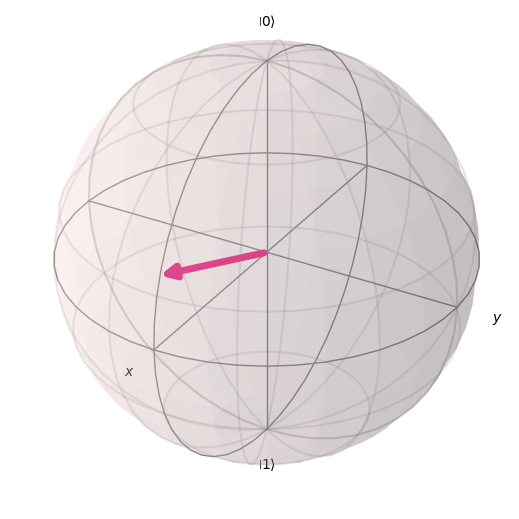

In [15]:
plot_bloch_vector(bloch_vector)